In [7]:
from collections import Counter


In [8]:
import os
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
os.environ["TORCH_USE_CUDA_DSA"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
print("Environment set ")

Environment set 


In [ ]:


import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split
from sentence_transformers import SentenceTransformer
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter


In [10]:
knowledge_path = '/home/suman/research/key_value_retrieval/datasettable.csv'
knowledge_df = pd.read_csv(knowledge_path)
knowledge_df['key_json'] = knowledge_df['key_json'].astype(str)

unique_keys = knowledge_df['key_json'].unique()
key_to_id = {key: i for i, key in enumerate(unique_keys)}
id_to_key = {i: key for key, i in key_to_id.items()}
num_classes = len(unique_keys)
print(f"Number of JSON classes: {num_classes}")

Number of JSON classes: 100


In [11]:
# Pre‑compute embeddings for all JSON keys (MiniLM)
embedder = SentenceTransformer('all-MiniLM-L6-v2')
key_embeddings = embedder.encode(unique_keys, show_progress_bar=True)
key_embeddings = key_embeddings / np.linalg.norm(key_embeddings, axis=1, keepdims=True)
key_emb_tensor = torch.tensor(key_embeddings, dtype=torch.float32)  # (num_classes, 384)

/home/suman/research/key_value_retrival/key/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Batches: 100%|██████████| 4/4 [00:00<00:00, 73.50it/s]


In [12]:
# 2. Build training dataset (questions -> correct JSON key ID)
# ------------------------------
medquad_path = "/home/suman/research/key_value_retrieval/data/medquad.csv"
df_medquad = pd.read_csv(medquad_path)
df_medquad = df_medquad[['question']].dropna().reset_index(drop=True)
df_medquad['question'] = df_medquad['question'].astype(str).str.strip()
df_medquad = df_medquad.head(5000)  

In [13]:
# Encode questions and find closest JSON key (cosine similarity)
q_embs = embedder.encode(df_medquad['question'].tolist(), show_progress_bar=True)
q_embs = q_embs / np.linalg.norm(q_embs, axis=1, keepdims=True)
sim_matrix = np.dot(q_embs, key_embeddings.T)
best_key_ids = np.argmax(sim_matrix, axis=1)
df_medquad['target_id'] = best_key_ids

train_df, valid_df = train_test_split(df_medquad, test_size=0.1, random_state=42)

Batches: 100%|██████████| 157/157 [00:01<00:00, 154.94it/s]


In [14]:
# -----------------------------
# ------------------------------
class SimpleTokenizer:
    def __init__(self, texts, max_vocab=10000):
        self.PAD = "<pad>"
        self.SOS = "<sos>"
        self.EOS = "<eos>"
        self.UNK = "<unk>"
        self.special_tokens = [self.PAD, self.SOS, self.EOS, self.UNK]
        self.word2idx = {}
        self.idx2word = {}
        self.build_vocab(texts, max_vocab)

    def tokenize(self, text):
        return text.lower().strip().split()

    def build_vocab(self, texts, max_vocab):
        counter = Counter()
        for text in texts:
            counter.update(self.tokenize(text))
        for tok in self.special_tokens:
            self.word2idx[tok] = len(self.word2idx)
        remaining = max_vocab - len(self.special_tokens)
        most_common = counter.most_common(remaining)
        for word, freq in most_common:
            if freq >= 2:
                self.word2idx[word] = len(self.word2idx)
        self.idx2word = {v: k for k, v in self.word2idx.items()}

    def encode(self, text, max_len=None, add_special_tokens=False):
        ids = [self.word2idx.get(t, self.word2idx[self.UNK]) for t in self.tokenize(text)]
        if max_len and len(ids) > max_len:
            ids = ids[:max_len]
        if add_special_tokens:
            ids = [self.word2idx[self.SOS]] + ids + [self.word2idx[self.EOS]]
        return ids

    def decode(self, ids, skip_special_tokens=True):
        words = []
        for i in ids:
            if i not in self.idx2word:
                continue
            w = self.idx2word[i]
            if skip_special_tokens and w in self.special_tokens:
                continue
            words.append(w)
        return " ".join(words)

    @property
    def vocab_size(self):
        return len(self.word2idx)

    @property
    def pad_token_id(self):
        return self.word2idx[self.PAD]

    @property
    def sos_token_id(self):
        return self.word2idx[self.SOS]

    @property
    def eos_token_id(self):
        return self.word2idx[self.EOS]

tokenizer = SimpleTokenizer(train_df['question'].tolist(), max_vocab=10000)
print(f"Vocabulary size: {tokenizer.vocab_size}")

Vocabulary size: 1375


In [15]:

TOP_K = 10

def get_top_k_knowledge(question_text, k=TOP_K):
    q_emb = embedder.encode(question_text, normalize_embeddings=True)
    scores = np.dot(key_embeddings, q_emb)
    top_indices = np.argsort(scores)[-k:][::-1]
    return torch.tensor(key_embeddings[top_indices], dtype=torch.float32)

class JSONDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=128):
        self.df = df
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        question = row['question']
        target_id = row['target_id']
        enc_ids = self.tokenizer.encode(question, max_len=self.max_len, add_special_tokens=False)
        return {
            "encoder_input_ids": torch.tensor(enc_ids, dtype=torch.long),
            "target_id": torch.tensor(target_id, dtype=torch.long)
        }

class JSONDatasetWithKnowledge(JSONDataset):
    def __getitem__(self, idx):
        base = super().__getitem__(idx)
        base['knowledge'] = self.df.iloc[idx]['knowledge']
        return base

def collate_fn_knowledge(batch, pad_token_id):
    enc_ids = pad_sequence([x["encoder_input_ids"] for x in batch],
                           batch_first=True, padding_value=pad_token_id)
    target_ids = torch.stack([x["target_id"] for x in batch])
    knowledge = torch.stack([x["knowledge"] for x in batch])   # (batch, TOP_K, 384)
    return {"encoder_input_ids": enc_ids, "target_id": target_ids, "knowledge": knowledge}

# Pre‑compute knowledge vectors for all questions
train_df['knowledge'] = train_df['question'].apply(lambda q: get_top_k_knowledge(q))
valid_df['knowledge'] = valid_df['question'].apply(lambda q: get_top_k_knowledge(q))

train_dataset = JSONDatasetWithKnowledge(train_df, tokenizer, max_len=128)
valid_dataset = JSONDatasetWithKnowledge(valid_df, tokenizer, max_len=128)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True,
                          collate_fn=lambda b: collate_fn_knowledge(b, tokenizer.pad_token_id))
valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=False,
                          collate_fn=lambda b: collate_fn_knowledge(b, tokenizer.pad_token_id))


In [16]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, dropout, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers, batch_first=True,
                            bidirectional=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc_hidden = nn.Linear(hidden_dim * 2, hidden_dim)
        self.fc_cell = nn.Linear(hidden_dim * 2, hidden_dim)

    def forward(self, src):
        embedded = self.dropout(self.embedding(src))
        lengths = (src != 0).sum(dim=1).cpu()
        # Guard against zero-length sequences
        lengths = torch.clamp(lengths, min=1)
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        outputs, (hidden, cell) = self.lstm(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(outputs, batch_first=True)
        # Merge bidirectional
        hidden = hidden.view(self.lstm.num_layers, 2, src.size(0), self.lstm.hidden_size)
        cell = cell.view(self.lstm.num_layers, 2, src.size(0), self.lstm.hidden_size)
        hidden = torch.cat((hidden[:, 0], hidden[:, 1]), dim=2)
        cell = torch.cat((cell[:, 0], cell[:, 1]), dim=2)
        hidden = torch.tanh(self.fc_hidden(hidden))
        cell = torch.tanh(self.fc_cell(cell))
        # Use last layer for decoder initialisation
        hidden = hidden[-1].unsqueeze(0)   # (1, batch, hidden_dim)
        cell = cell[-1].unsqueeze(0)
        return outputs, hidden, cell

In [17]:
class Attention(nn.Module):
    def __init__(self, enc_hid_dim, dec_hid_dim):
        super().__init__()
        self.attn = nn.Linear(enc_hid_dim * 2 + dec_hid_dim, dec_hid_dim)
        self.v = nn.Parameter(torch.randn(dec_hid_dim))

    def forward(self, decoder_hidden, encoder_outputs, mask):
        # mask: (batch, src_len) - True for non‑padding positions
        src_len = encoder_outputs.shape[1]
        decoder_hidden = decoder_hidden.unsqueeze(1).repeat(1, src_len, 1)
        energy = torch.tanh(self.attn(torch.cat((encoder_outputs, decoder_hidden), dim=2)))
        scores = torch.matmul(energy, self.v)
        # Apply mask: set scores of padding positions to a very low value
        scores = scores.masked_fill(~mask, -1e9)   # mask is True for valid tokens
        weights = F.softmax(scores, dim=1)
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs).squeeze(1)
        return context, weights


In [18]:
class DecoderWithKnowledge(nn.Module):
    def __init__(self, output_dim, embed_dim, enc_hid_dim, dec_hid_dim,
                 knowledge_dim, num_layers=1, dropout=0.3):
        super().__init__()
        self.output_dim = output_dim
        self.embedding = nn.Embedding(output_dim, embed_dim, padding_idx=0)
        self.attention = Attention(enc_hid_dim, dec_hid_dim)
        self.knowledge_proj = nn.Linear(dec_hid_dim, knowledge_dim, bias=False)
        self.rnn = nn.LSTM(embed_dim + enc_hid_dim*2 + knowledge_dim, dec_hid_dim,
                           num_layers, batch_first=True, dropout=dropout)
        self.fc_out = nn.Linear(dec_hid_dim + enc_hid_dim*2 + knowledge_dim + embed_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_token, decoder_hidden, decoder_cell, encoder_outputs, src_mask, knowledge_memory):
        embedded = self.dropout(self.embedding(input_token))
        # Encoder attention
        context_enc, _ = self.attention(decoder_hidden[-1], encoder_outputs, src_mask)
        context_enc = context_enc.unsqueeze(1)
        # Knowledge attention over top‑k JSON embeddings
        query = self.knowledge_proj(decoder_hidden[-1]).unsqueeze(1)        # (batch, 1, knw_dim)
        scores = torch.matmul(query, knowledge_memory.transpose(1,2))       # (batch, 1, TOP_K)
        weights = F.softmax(scores / (knowledge_memory.size(-1)**0.5), dim=-1)
        context_knw = torch.matmul(weights, knowledge_memory).squeeze(1)    # (batch, knw_dim)
        context_knw = context_knw.unsqueeze(1)
        # RNN input
        rnn_input = torch.cat((embedded, context_enc, context_knw), dim=2)
        output, (hidden, cell) = self.rnn(rnn_input, (decoder_hidden, decoder_cell))
        # Final prediction (single step)
        rnn_out = output.squeeze(1)
        emb = embedded.squeeze(1)
        enc_ctx = context_enc.squeeze(1)
        knw_ctx = context_knw.squeeze(1)
        combined = torch.cat((rnn_out, enc_ctx, knw_ctx, emb), dim=1)
        logits = self.fc_out(combined)   # (batch, num_classes)
        return logits.unsqueeze(1), hidden, cell


In [19]:
class Seq2SeqClassifier(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, knowledge_memory):
        encoder_outputs, hidden, cell = self.encoder(src)
        mask = (src != 0)   # boolean mask of valid tokens
        batch_size = src.size(0)
        input_token = torch.full((batch_size, 1), tokenizer.sos_token_id, device=src.device)
        logits, _, _ = self.decoder(input_token, hidden, cell, encoder_outputs, mask, knowledge_memory)
        return logits.squeeze(1)   # (batch, num_classes)


/home/suman/research/key_value_retrival/key/lib/python3.10/site-packages/torch/nn/modules/rnn.py:1009: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


Trainable params: 4,555,236


Validating: 100%|██████████| 8/8 [00:00<00:00, 68.06it/s]


Epoch 1: Train Loss = 3.6205, Val Loss = 3.2165, Val Acc = 0.2200


Validating: 100%|██████████| 8/8 [00:00<00:00, 98.15it/s]


Epoch 2: Train Loss = 3.0449, Val Loss = 2.9864, Val Acc = 0.2280


... (192 outputs left out)

Validating: 100%|██████████| 8/8 [00:00<00:00, 114.10it/s]


Epoch 99: Train Loss = 0.3752, Val Loss = 1.6591, Val Acc = 0.6160


Validating: 100%|██████████| 8/8 [00:00<00:00, 113.34it/s]


Epoch 100: Train Loss = 0.3747, Val Loss = 1.6591, Val Acc = 0.6160


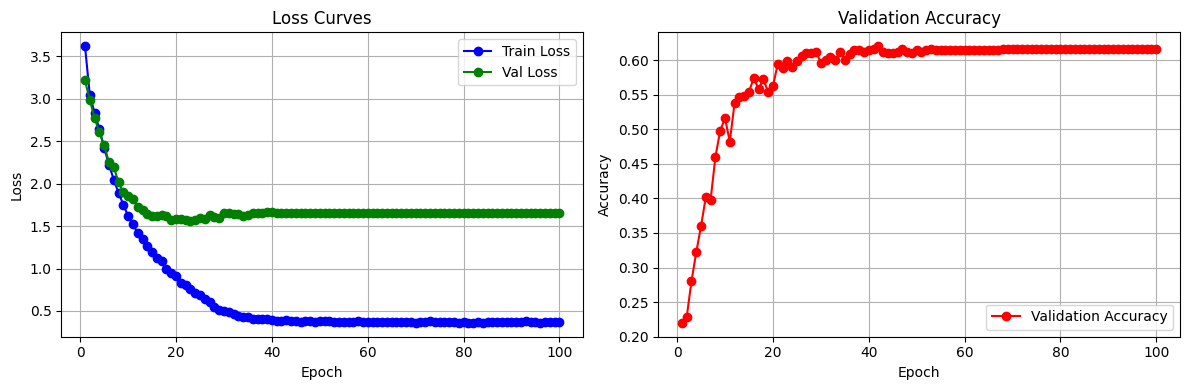

Seq2SeqClassifier(
  (encoder): Encoder(
    (embedding): Embedding(1375, 128, padding_idx=0)
    (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
    (dropout): Dropout(p=0.3, inplace=False)
    (fc_hidden): Linear(in_features=512, out_features=256, bias=True)
    (fc_cell): Linear(in_features=512, out_features=256, bias=True)
  )
  (decoder): DecoderWithKnowledge(
    (embedding): Embedding(100, 128, padding_idx=0)
    (attention): Attention(
      (attn): Linear(in_features=768, out_features=256, bias=True)
    )
    (knowledge_proj): Linear(in_features=256, out_features=384, bias=False)
    (rnn): LSTM(1024, 256, batch_first=True, dropout=0.3)
    (fc_out): Linear(in_features=1280, out_features=100, bias=True)
    (dropout): Dropout(p=0.3, inplace=False)
  )
)

In [20]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

encoder = Encoder(tokenizer.vocab_size, embed_dim=128, hidden_dim=256,
                  num_layers=2, dropout=0.3, pad_idx=tokenizer.pad_token_id)
decoder = DecoderWithKnowledge(output_dim=num_classes, embed_dim=128,
                               enc_hid_dim=256, dec_hid_dim=256,
                               knowledge_dim=384, num_layers=1, dropout=0.3)
model = Seq2SeqClassifier(encoder, decoder).to(device)
print(f"Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

# ------------------------------
# 7. Training loop (with validation loss)
# ------------------------------
epochs = 100
train_losses = []
val_losses = []
val_accs = []
best_acc = 0.0

for epoch in range(epochs):
    model.train()
    total_train_loss = 0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [train]"):
        src = batch["encoder_input_ids"].to(device)
        targets = batch["target_id"].to(device)
        knowledge = batch["knowledge"].to(device)

        optimizer.zero_grad()
        logits = model(src, knowledge)
        loss = criterion(logits, targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_train_loss += loss.item()
    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation
    model.eval()
    total_val_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for batch in tqdm(valid_loader, desc="Validating"):
            src = batch["encoder_input_ids"].to(device)
            targets = batch["target_id"].to(device)
            knowledge = batch["knowledge"].to(device)
            logits = model(src, knowledge)
            loss = criterion(logits, targets)
            total_val_loss += loss.item()
            preds = logits.argmax(dim=1)
            correct += (preds == targets).sum().item()
            total += targets.size(0)
    avg_val_loss = total_val_loss / len(valid_loader)
    val_losses.append(avg_val_loss)
    acc = correct / total
    val_accs.append(acc)

    print(f"Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Val Loss = {avg_val_loss:.4f}, Val Acc = {acc:.4f}")

    scheduler.step(avg_val_loss)   # use validation loss for LR scheduling
    if acc > best_acc:
        best_acc = acc
        torch.save(model.state_dict(), "json output/best_json_model.pt")

# ------------------------------
# 8. Plot training curves
# ------------------------------
epochs_range = range(1, epochs + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, 'b-o', label='Train Loss')
plt.plot(epochs_range, val_losses, 'g-o', label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curves')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, val_accs, 'r-o', label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Validation Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('json output/training_curves_json.png', dpi=150)
plt.show()


# ------------------------------/kaggle/working
model.load_state_dict(torch.load("/home/suman/research/key_value_retrieval/json output/best_json_model.pt"))
model.eval()


In [21]:
def predict_json_key(question):
    enc_ids = tokenizer.encode(question, max_len=128, add_special_tokens=False)
    src = torch.tensor([enc_ids], device=device)
    knw = get_top_k_knowledge(question).unsqueeze(0).to(device)   # (1, TOP_K, 384)
    with torch.no_grad():
        logits = model(src, knw)
        pred_id = logits.argmax(dim=1).item()
    return id_to_key[pred_id]

test_questions = [
    "What is glaucoma?",
    "What causes high blood pressure?",
    "What are the symptoms of diabetes?",
    "How to treat hypertension?",
    "What is the treatment for COVID-19?"
]

print("\n" + "="*70)
print("PREDICTED JSON KEYS AND RETRIEVED ANSWERS")
print("="*70)
for q in test_questions:
    pred_key = predict_json_key(q)
    answer_row = knowledge_df[knowledge_df['key_json'] == pred_key]
    answer = answer_row.iloc[0]['answer'] if not answer_row.empty else "Answer not found."
    print(f"\nQuestion: {q}")
    print(f"Predicted JSON Key: {pred_key}")
    print(f"Retrieved Answer: {answer}")
    print("-"*80)


PREDICTED JSON KEYS AND RETRIEVED ANSWERS

Question: What is glaucoma?
Predicted JSON Key: {"focus": "Glaucoma", "intent": "treatment", "subject": "laser therapy"}
Retrieved Answer: Laser trabeculoplasty helps fluid drain out of the eye to lower intraocular pressure.
--------------------------------------------------------------------------------

Question: What causes high blood pressure?
Predicted JSON Key: {"focus": "High Blood Pressure", "intent": "causes", "subject": "genetics"}
Retrieved Answer: A family history of hypertension increases the likelihood that an individual will develop the disease.
--------------------------------------------------------------------------------

Question: What are the symptoms of diabetes?
Predicted JSON Key: {"focus": "Diabetes", "intent": "symptoms", "subject": "silent disease"}
Retrieved Answer: It is often silent; serious complications can occur before a person even knows they have it.
----------------------------------------------------------